# UTS Data Mining: Perdagangan Indonesia dan Uni Eropa per Komoditas (2019-2026)
**Nama:** Muhammad Farid Zaki  **NIM:** 1003240010  **Kelas:** IF207

> Notebook ini mengikuti kerangka makalah (Bab 1 sampai 5). Sebelum dikumpulkan: *Runtime → Restart session and run all* harus berjalan tanpa error.

**Sumber data:** Eurostat Comext, dataset DS-045409 *EU trade since 1988 by HS2-4-6 and CN8* (lisensi CC BY 4.0).

## Bab 1. Business Problem dan Tujuan Analisis


| Bagian | Isi |
|---|---|
| Judul proyek | Analisis perdagangan Indonesia dan Uni Eropa per komoditas menjelang berlakunya IEU-CEPA dan EUDR |
| Konteks bisnis | Uni Eropa (UE) termasuk pasar ekspor penting buat Indonesia, dan selama ini Indonesia selalu surplus dagang dengan UE. Tanggal 21 November 2026 Indonesia dan UE resmi menandatangani IEU-CEPA dan Investment Protection Agreement (IPA) di Brussel. Lewat IEU-CEPA, bea masuk untuk lebih dari 90% barang yang diperdagangkan akan dihapus, dan perjanjian ini ditargetkan mulai berlaku 1 Januari 2027 setelah diratifikasi kedua pihak [1][2]. Pemerintah juga menargetkan ekspor tahunan Indonesia ke UE naik sekitar US$3,82 sampai 5,78 miliar dalam lima tahun ke depan [2]. Di sisi lain, fasilitas tarif GSP untuk Indonesia habis akhir 2026 [1], dan aturan EUDR (anti-deforestasi) mulai berlaku 30 Desember 2026 untuk perusahaan besar dan menengah [3]. Untuk Indonesia, komoditas yang kena EUDR adalah sawit, kopi, kakao, kayu dan karet [4]. Data Januari 2019 sampai September 2026 yang saya pakai menggambarkan kondisi sebelum kedua aturan ini berjalan, jadi bisa dipakai sebagai baseline. |
| Masalah bisnis | Eksportir dan pemerintah perlu tahu komoditas apa yang sedang naik atau turun di pasar UE, apakah komoditas yang kena EUDR polanya beda dengan yang lain, dan negara UE mana yang paling banyak menyerap ekspor Indonesia. Informasi ini dipakai untuk menentukan ke mana promosi dan pendampingan diarahkan. |
| Stakeholder | Kementerian Perdagangan dan ITPC di Eropa, asosiasi eksportir (sawit, karet, kopi, kakao, mebel), eksportir UMKM, dan analis kebijakan perdagangan. |
| Tujuan bisnis | Menemukan komoditas dan negara tujuan yang perlu diprioritaskan, serta komoditas yang berisiko, sebagai bahan untuk strategi ekspor ke UE. |
| Masalah data | Dari data bulanan per negara UE dan per bab HS2, saya ingin melihat tren, komposisi, konsentrasi negara tujuan, dan pola naik/turun nilai ekspor dibanding tahun sebelumnya, lalu membandingkan kelompok EUDR dan non-EUDR. |
| Target | naik_yoy: bernilai 1 kalau nilai ekspor Indonesia untuk suatu bab HS2 ke suatu negara UE di bulan tertentu lebih tinggi dari bulan yang sama tahun lalu, dan 0 kalau tidak. Target ini disiapkan untuk tahap modeling (klasifikasi) berikutnya. |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
os.makedirs('figures', exist_ok=True)

RAW_LOCAL = 'data/raw/perdagangan_id_ue_hs2_bulanan.csv'
RAW_URL = ('https://raw.githubusercontent.com/Zetakai/uts-data-mining/main/'
           'data/raw/perdagangan_id_ue_hs2_bulanan.csv')
RAW = RAW_LOCAL if os.path.exists(RAW_LOCAL) else RAW_URL

# Data mentah: JANGAN ditimpa
df_raw = pd.read_csv(RAW)
df = df_raw.copy()
df.shape

(212378, 7)

## Bab 2. Deskripsi Dataset (Data Understanding)

In [2]:
df.head()

,periode,kode_negara,hs2,deskripsi_hs2,arus,nilai_eur,berat_100kg
0,2019-01,AT,3,"FISH AND CRUSTACEANS, MOLLUSCS AND OTHER AQUAT...",1,3316,0.52
1,2019-01,AT,4,DAIRY PRODUCE; BIRDS' EGGS; NATURAL HONEY; EDI...,2,18628,21.79
2,2019-01,AT,5,"PRODUCTS OF ANIMAL ORIGIN, NOT ELSEWHERE SPECI...",2,212240,38.16
3,2019-01,AT,8,EDIBLE FRUIT AND NUTS; PEEL OF CITRUS FRUIT OR...,1,76971,640.00
4,2019-01,AT,9,"COFFEE, TEA, MATE AND SPICES",1,228713,"1,201.41"


In [3]:
print('shape:', df.shape)
df.info()

shape: (212378, 7)
<class 'pandas.DataFrame'>
RangeIndex: 212378 entries, 0 to 212377
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   periode        212378 non-null  str    
 1   kode_negara    212378 non-null  str    
 2   hs2            212378 non-null  int64  
 3   deskripsi_hs2  212378 non-null  str    
 4   arus           212378 non-null  int64  
 5   nilai_eur      212378 non-null  int64  
 6   berat_100kg    212378 non-null  float64
dtypes: float64(1), int64(3), str(3)
memory usage: 11.3 MB


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
periode,212378,93,2025-10,2445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kode_negara,212378,27,DE,15124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hs2,"212,378.00",NaN,NaN,NaN,53.41,26.94,1.00,32.00,56.00,75.00,99.00
deskripsi_hs2,212378,97,"NUCLEAR REACTORS, BOILERS, MACHINERY AND MECHA...",4829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arus,"212,378.00",NaN,NaN,NaN,1.43,0.50,1.00,1.00,1.00,2.00,2.00
nilai_eur,"212,378.00",NaN,NaN,NaN,"975,736.32","5,026,537.98",0.00,"2,614.00","42,781.50","306,929.00","491,925,545.00"
berat_100kg,"212,378.00",NaN,NaN,NaN,"5,660.44","59,075.25",0.00,0.58,32.30,570.01,"6,541,460.00"


In [5]:
# Kamus kolom
kamus = pd.DataFrame({
    'kolom': df.columns,
    'arti': ['Bulan pencatatan (YYYY-MM)',
             'Kode negara anggota UE pelapor (ISO-2 versi Eurostat)',
             'Kode bab Harmonized System 2 digit (kelompok komoditas)',
             'Nama bab HS2 (bahasa Inggris, dari Eurostat)',
             'Arah arus: 1 = impor UE dari Indonesia (ekspor RI), 2 = ekspor UE ke Indonesia (impor RI)',
             'Nilai perdagangan dalam euro',
             'Berat bersih dalam satuan 100 kg'],
    'tipe_saat_ini': df.dtypes.astype(str).values,
})
kamus

,kolom,arti,tipe_saat_ini
0,periode,Bulan pencatatan (YYYY-MM),str
1,kode_negara,Kode negara anggota UE pelapor (ISO-2 versi Eu...,str
2,hs2,Kode bab Harmonized System 2 digit (kelompok k...,int64
3,deskripsi_hs2,"Nama bab HS2 (bahasa Inggris, dari Eurostat)",str
4,arus,Arah arus: 1 = impor UE dari Indonesia (ekspor...,int64
5,nilai_eur,Nilai perdagangan dalam euro,int64
6,berat_100kg,Berat bersih dalam satuan 100 kg,float64


Dataset yang saya pakai berukuran 212.378 baris dan 7 kolom. Sumbernya Eurostat Comext (dataset DS-045409). Datanya mencakup Januari 2019 sampai September 2026, 27 negara anggota UE, 97 bab HS2, dan dua arah perdagangan.

| Kolom | Arti kolom | Tipe data saat ini | Sudah sesuai maknanya? | Peran sementara |
|---|---|---|---|---|
| periode | Bulan pencatatan | str (teks) | Belum, seharusnya tanggal | identifier (waktu) |
| kode_negara | Negara anggota UE yang melaporkan | str | Sudah | identifier / feature |
| hs2 | Kode bab komoditas HS 2 digit | int64 | Belum, ini kode kategori dan nol di depannya hilang (01 jadi 1) | identifier / feature |
| deskripsi_hs2 | Nama bab HS2 | str | Sudah | keterangan |
| arus | 1 = ekspor RI ke UE, 2 = impor RI dari UE | int64 | Belum, ini kategori bukan angka | feature (filter) |
| nilai_eur | Nilai perdagangan dalam euro | int64 | Sudah | dasar target |
| berat_100kg | Berat bersih dalam satuan 100 kg | float64 | Sudah, tapi ada nilai 0 yang aneh | feature |

Satu baris berarti ada perdagangan yang tercatat untuk kombinasi tersebut. Kalau tidak ada perdagangan, barisnya tidak muncul.

## Bab 3. Data Profiling

> Setiap temuan harus punya bukti dari kode.

### 3.1 Ukuran, skema dan tipe data

In [6]:
print('Baris x kolom:', df.shape)
print('Contoh hs2 setelah dibaca pandas:', sorted(df['hs2'].unique())[:5])
print('Jumlah bab HS2 unik:', df['hs2'].nunique())
print('Rentang periode:', df['periode'].min(), 's.d.', df['periode'].max(), '| tipe:', df['periode'].dtype)

Baris x kolom: (212378, 7)
Contoh hs2 setelah dibaca pandas: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Jumlah bab HS2 unik: 97
Rentang periode: 2019-01 s.d. 2026-09 | tipe: str


Dari hasil di atas, kolom hs2 ternyata terbaca sebagai angka, sehingga kode 01 sampai 09 berubah jadi 1 sampai 9. HS2 adalah kode kategori, jadi tidak boleh diperlakukan sebagai angka. Kolom periode juga masih berupa teks dan arus masih berupa kode 1/2. Ketiga kolom ini saya perbaiki di Bab 4.

### 3.2 Missing values dan kelengkapan panel

In [7]:
miss = df.isna().sum().to_frame('jumlah_missing')
miss['persen'] = (miss['jumlah_missing'] / len(df) * 100).round(2)
display(miss)

# Missing yang 'tersembunyi': kombinasi negara x HS2 x arus x bulan yang tidak muncul sama sekali
n_kombinasi_penuh = df['periode'].nunique() * df['kode_negara'].nunique() * df['hs2'].nunique() * df['arus'].nunique()
print(f'Kombinasi teoretis: {n_kombinasi_penuh:,} | tercatat: {len(df):,} '
      f'| tidak tercatat: {1 - len(df)/n_kombinasi_penuh:.1%}')

,jumlah_missing,persen
periode,0,0.00
kode_negara,0,0.00
hs2,0,0.00
deskripsi_hs2,0,0.00
arus,0,0.00
nilai_eur,0,0.00
berat_100kg,0,0.00


Kombinasi teoretis: 487,134 | tercatat: 212,378 | tidak tercatat: 56.4%


Tidak ada sel yang kosong, semua kolom 0%. Tapi kalau dilihat lebih jauh, dari 487.134 kombinasi bulan, negara, HS2 dan arus yang mungkin ada, sekitar 56,4% tidak tercatat sama sekali. Kombinasi yang tidak tercatat ini biasanya berarti tidak ada perdagangan atau nilainya terlalu kecil untuk dilaporkan. Untuk target, kalau bulan yang sama tahun lalu tidak tercatat, saya tidak bisa memastikan nilainya nol, jadi targetnya saya biarkan NaN.

### 3.3 Duplikat

In [8]:
kunci = ['periode', 'kode_negara', 'hs2', 'arus']
print('Baris duplikat penuh   :', df.duplicated().sum())
print('Duplikat pada kunci    :', df.duplicated(kunci).sum())

Baris duplikat penuh   : 0
Duplikat pada kunci    : 0


Tidak ada baris duplikat, dan kombinasi periode, negara, HS2 dan arus juga tidak ada yang muncul dua kali.

### 3.4 Nilai unik dan kardinalitas

In [9]:
display(df[['kode_negara', 'hs2', 'deskripsi_hs2', 'arus']].nunique().to_frame('n_unik'))
print('Kode negara:', sorted(df['kode_negara'].unique()))
# Apakah satu kode HS2 selalu punya satu deskripsi (dan sebaliknya)?
print('HS2 dengan >1 deskripsi :', (df.groupby('hs2')['deskripsi_hs2'].nunique() > 1).sum())
print('Deskripsi dengan >1 HS2 :', (df.groupby('deskripsi_hs2')['hs2'].nunique() > 1).sum())
print('Deskripsi dengan spasi berlebih:', (df['deskripsi_hs2'] != df['deskripsi_hs2'].str.strip()).sum())
df.loc[df['hs2'].isin([99, 98, 77]), ['hs2', 'deskripsi_hs2']].drop_duplicates()

,n_unik
kode_negara,27
hs2,97
deskripsi_hs2,97
arus,2


Kode negara: ['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HR', 'HU', 'IE', 'IT', 'LT', 'LU', 'LV', 'MT', 'NL', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK']
HS2 dengan >1 deskripsi : 0
Deskripsi dengan >1 HS2 : 0


Deskripsi dengan spasi berlebih: 0


,hs2,deskripsi_hs2
231,99,Other products


Ada 27 kode negara (semua anggota UE), 97 bab HS2, dan 97 deskripsi yang pasangannya satu-satu. Tidak ada penulisan berbeda untuk hal yang sama dan tidak ada spasi berlebih. Satu-satunya yang aneh adalah HS 99 "Other products", kode khusus/rahasia dari Eurostat yang tidak menunjuk ke komoditas tertentu.

### 3.5 Nilai tidak valid dan konsistensi antar kolom

In [10]:
cek = pd.Series({
    'nilai_eur < 0': (df['nilai_eur'] < 0).sum(),
    'berat_100kg < 0': (df['berat_100kg'] < 0).sum(),
    'nilai_eur == 0': (df['nilai_eur'] == 0).sum(),
    'berat == 0 tetapi nilai > 0': ((df['berat_100kg'] == 0) & (df['nilai_eur'] > 0)).sum(),
    'nilai == 0 tetapi berat > 0': ((df['nilai_eur'] == 0) & (df['berat_100kg'] > 0)).sum(),
    'periode di luar 2019-2026': (~df['periode'].str[:4].between('2019', '2026')).sum(),
}, name='jumlah_baris')
display(cek.to_frame())
print('HS2 terbanyak pada kasus berat == 0 & nilai > 0:')
df[(df['berat_100kg'] == 0) & (df['nilai_eur'] > 0)]['hs2'].value_counts().head(6)

,jumlah_baris
nilai_eur < 0,0
berat_100kg < 0,0
nilai_eur == 0,216
berat == 0 tetapi nilai > 0,7255
nilai == 0 tetapi berat > 0,145
periode di luar 2019-2026,0


HS2 terbanyak pada kasus berat == 0 & nilai > 0:


hs2
99    843
91    478
71    394
75    293
65    236
49    203
Name: count, dtype: int64

Hasil pengecekan:
- Tidak ada nilai negatif dan tidak ada periode di luar rentang.
- Ada 216 baris yang nilainya 0 euro, jadi tidak memberi informasi apa-apa.
- Ada 7.255 baris yang beratnya 0 tapi nilainya lebih dari 0, padahal barang yang dijual pasti punya berat. Paling banyak ada di HS 99 (kode khusus), 91 (jam), 71 (perhiasan/logam mulia) dan 75 (nikel). Menurut saya penyebabnya karena berat dicatat dalam satuan 100 kg, jadi kiriman di bawah 50 kg dibulatkan jadi 0. Nilai euronya tetap bisa dipakai, beratnya saja yang tidak.
- Ada 145 baris yang nilainya 0 tapi beratnya lebih dari 0.

### 3.6 Distribusi dan outlier

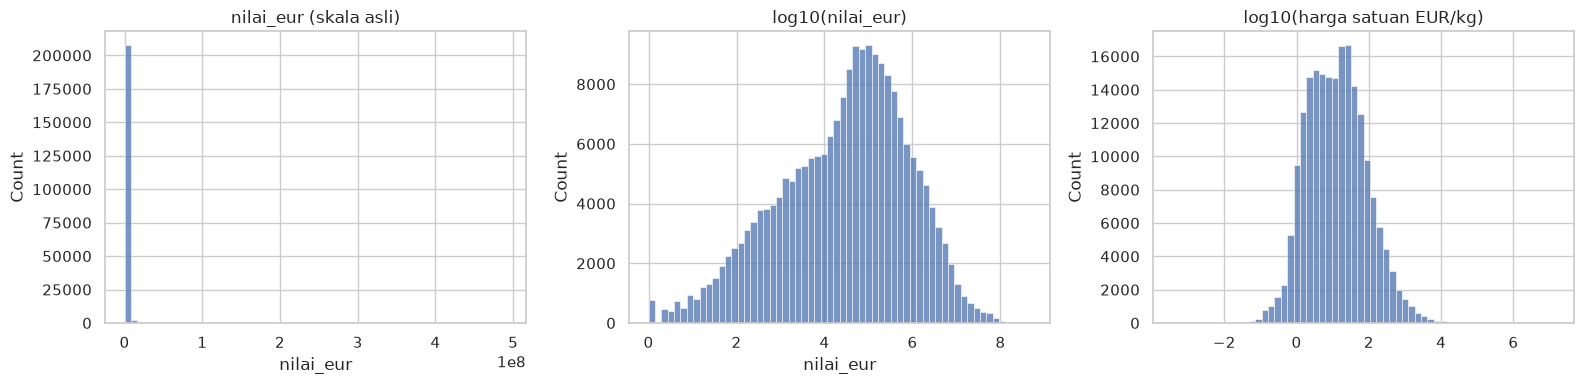

Skewness nilai_eur: 17.4
Kuantil harga satuan EUR/kg:


,EUR/kg
p1,0.22
p25,3.02
median,12.29
p75,45.59
p99,"1,594.46"
p99.9,"15,470.91"


Outlier nilai_eur menurut aturan IQR: 15.9% baris


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['nilai_eur'], bins=60, ax=axes[0])
axes[0].set_title('nilai_eur (skala asli)')
sns.histplot(np.log10(df.loc[df['nilai_eur'] > 0, 'nilai_eur']), bins=60, ax=axes[1])
axes[1].set_title('log10(nilai_eur)')
harga = df['nilai_eur'] / (df['berat_100kg'] * 100)
harga = harga.replace([np.inf, -np.inf], np.nan).dropna()
sns.histplot(np.log10(harga[harga > 0]), bins=60, ax=axes[2])
axes[2].set_title('log10(harga satuan EUR/kg)')
plt.tight_layout(); plt.savefig('figures/p1_distribusi.png', dpi=130); plt.show()

print('Skewness nilai_eur:', round(df['nilai_eur'].skew(), 1))
print('Kuantil harga satuan EUR/kg:')
kq = harga.quantile([.01, .25, .5, .75, .99, .999]).to_frame('EUR/kg')
kq.index = ['p1', 'p25', 'median', 'p75', 'p99', 'p99.9']
display(kq)
q1, q3 = df['nilai_eur'].quantile([.25, .75])
print(f'Outlier nilai_eur menurut aturan IQR: {(df["nilai_eur"] > q3 + 1.5*(q3-q1)).mean():.1%} baris')

In [12]:
# Harga satuan ekstrem: kesalahan data atau barang mahal yang sah?
tmp = df.assign(harga_eur_kg=df['nilai_eur'] / (df['berat_100kg'] * 100)).replace([np.inf], np.nan)
tmp.nlargest(8, 'harga_eur_kg')[['periode', 'kode_negara', 'hs2', 'deskripsi_hs2', 'arus', 'nilai_eur', 'berat_100kg', 'harga_eur_kg']]

,periode,kode_negara,hs2,deskripsi_hs2,arus,nilai_eur,berat_100kg,harga_eur_kg
118462,2023-03,IE,88,"AIRCRAFT, SPACECRAFT, AND PARTS THEREOF",2,28056878,0.02,"14,028,439.00"
108139,2026-08,FR,91,CLOCKS AND WATCHES AND PARTS THEREOF,2,723645,0.01,"723,645.00"
49134,2025-02,CZ,93,ARMS AND AMMUNITION; PARTS AND ACCESSORIES THE...,2,616118,0.01,"616,118.00"
107517,2026-06,FR,91,CLOCKS AND WATCHES AND PARTS THEREOF,2,3161984,0.07,"451,712.00"
1742,2019-07,AT,28,INORGANIC CHEMICALS; ORGANIC OR INORGANIC COMP...,2,800911,0.02,"400,455.50"
94997,2023-01,FR,91,CLOCKS AND WATCHES AND PARTS THEREOF,2,398500,0.01,"398,500.00"
106888,2026-04,FR,91,CLOCKS AND WATCHES AND PARTS THEREOF,2,360770,0.01,"360,770.00"
22050,2025-03,BE,30,PHARMACEUTICAL PRODUCTS,1,7576624,0.24,"315,692.67"


Distribusi nilai_eur sangat miring ke kanan (skewness 17,4). Kalau pakai aturan IQR, 15,9% baris dianggap outlier. Menurut saya 15,9% terlalu banyak kalau semuanya dianggap kesalahan data. Di data perdagangan memang ada sedikit komoditas bernilai sangat besar dan banyak transaksi kecil, jadi grafiknya saya buat dengan skala log supaya terbaca.

Harga satuan mediannya 12,3 EUR/kg, persentil 99 sekitar 1.594 EUR/kg, dan persentil 99,9 sekitar 15.471 EUR/kg. Nilai yang paling ekstrem, misalnya pesawat ke Irlandia dengan harga 14 juta EUR/kg, muncul karena beratnya tercatat sangat kecil (0,02 × 100 kg = 2 kg). Harga satuan untuk baris seperti ini tidak bisa dipercaya, sedangkan nilai euronya masih benar. Karena itu baris ekstrem tidak saya hapus, hanya saya tandai di kolom outlier_harga.

### 3.7 Distribusi target

Definisi target yang saya pakai: untuk baris ekspor RI ke UE, naik_yoy = 1 kalau nilai_eur bulan ini lebih besar dari nilai bulan yang sama tahun lalu (negara dan HS2 yang sama), 0 kalau tidak, dan NaN kalau tahun lalu tidak ada catatannya. Seluruh tahun 2019 otomatis NaN karena tidak punya pembanding.

In [13]:
eks = df[df['arus'] == 1].copy()
eks['tgl'] = pd.to_datetime(eks['periode'])
lalu = eks[['tgl', 'kode_negara', 'hs2', 'nilai_eur']].copy()
lalu['tgl'] = lalu['tgl'] + pd.DateOffset(years=1)
eks = eks.merge(lalu.rename(columns={'nilai_eur': 'nilai_tahun_lalu'}),
                on=['tgl', 'kode_negara', 'hs2'], how='left')
eks['naik_yoy_awal'] = np.where(eks['nilai_tahun_lalu'].isna(), np.nan,
                                (eks['nilai_eur'] > eks['nilai_tahun_lalu']).astype(float))
dist = eks['naik_yoy_awal'].value_counts(dropna=False).rename({1.0: 'naik (1)', 0.0: 'tidak naik (0)'})
display(pd.DataFrame({'jumlah': dist, 'persen': (dist / dist.sum() * 100).round(1)}))

,jumlah,persen
naik_yoy_awal,,
naik (1),44999,37.50
tidak naik (0),42954,35.80
NaN,32166,26.80


Dari baris ekspor, 37,5% naik, 35,8% tidak naik, dan 26,8% tidak punya pembanding (NaN). Kalau hanya dilihat baris yang punya label, perbandingannya sekitar 51% banding 49%, jadi kelasnya seimbang dan saya tidak perlu oversampling atau teknik sejenis. Baris NaN tidak dipakai saat modeling.

### 3.8 Risiko untuk modeling (leakage)

| Kolom | Risiko | Keputusan |
|---|---|---|
| nilai_eur bulan berjalan | Target dihitung langsung dari kolom ini, jadi model sudah tahu jawabannya | Tidak boleh dipakai sebagai feature |
| nilai_tahun_lalu | Kalau dipakai bersama nilai_eur, target bisa ditebak 100% | Hanya boleh sebagai lag, jangan bersama nilai bulan berjalan |
| berat_100kg bulan berjalan | Diketahui bersamaan dengan nilai dan sangat berkorelasi | Pakai versi lag (bulan-bulan sebelumnya) |
| harga_eur_per_kg bulan berjalan | Turunan dari nilai_eur | Sama, hanya versi lag |
| Data 12 bulan terakhir | Masih bisa direvisi oleh Eurostat | Dipakai sebagai data uji dengan hati-hati |
| Pembagian train/test secara acak | Data bulan yang lebih baru bisa bocor ke data latih | Pembagian harus berdasarkan waktu |

### Ringkasan profiling


Secara format data ini sudah rapi: tidak ada missing, tidak ada duplikat, dan kategorinya konsisten. Masalahnya ada di makna dan konsistensi: tipe hs2/periode/arus yang salah, HS 99 yang bukan komoditas, nilai 0, berat 0 karena pembulatan satuan, harga satuan yang ekstrem, kombinasi yang tidak tercatat, dan risiko leakage pada target.

## Bab 4. Data Cleaning dan Cleaning Log

Data mentah df_raw tidak diubah. Semua langkah bekerja pada df (salinan), dan hasilnya disimpan ke berkas baru.

In [14]:
log = []   # cleaning log: diisi oleh setiap langkah
def catat(kolom, masalah, tindakan, alasan, sebelum, sesudah):
    log.append(dict(No=len(log)+1, Kolom=kolom, Masalah=masalah, Tindakan=tindakan, Alasan=alasan,
                    Baris_sebelum=sebelum, Baris_sesudah=sesudah))

df = df_raw.copy()
n_awal = len(df)

# 1. hs2 kehilangan nol di depan karena dibaca sebagai angka
n = len(df); df['hs2'] = df['hs2'].astype(int).astype(str).str.zfill(2)
catat('hs2', 'Dibaca sebagai int64, kode 01-09 jadi 1-9', 'Ubah ke string 2 digit (zfill)',
      'HS2 adalah kode kategori, bukan besaran; "01" harus tetap "01"', n, len(df))

# 2. periode masih teks
n = len(df); df['periode'] = pd.to_datetime(df['periode'], format='%Y-%m')
df['tahun'] = df['periode'].dt.year; df['bulan'] = df['periode'].dt.month
catat('periode', 'Bertipe teks', 'Ubah ke datetime, turunkan tahun dan bulan',
      'Perlu untuk urutan waktu, lag 12 bulan dan agregasi tahunan', n, len(df))

# 3. arus berupa angka kode
n = len(df); df['arus'] = df['arus'].map({1: 'Ekspor RI ke UE', 2: 'Impor RI dari UE'})
catat('arus', 'Kode 1/2 bertipe int, maknanya tidak terbaca', 'Map ke label teks',
      'Arus adalah kategori; label mencegah salah tafsir arah (sudut pandang UE vs RI)', n, len(df))

# 4. kode negara -> nama negara
NEGARA = {'AT': 'Austria', 'BE': 'Belgia', 'BG': 'Bulgaria', 'CY': 'Siprus', 'CZ': 'Ceko', 'DE': 'Jerman',
          'DK': 'Denmark', 'EE': 'Estonia', 'ES': 'Spanyol', 'FI': 'Finlandia', 'FR': 'Prancis', 'GR': 'Yunani',
          'HR': 'Kroasia', 'HU': 'Hungaria', 'IE': 'Irlandia', 'IT': 'Italia', 'LT': 'Lituania', 'LU': 'Luksemburg',
          'LV': 'Latvia', 'MT': 'Malta', 'NL': 'Belanda', 'PL': 'Polandia', 'PT': 'Portugal', 'RO': 'Rumania',
          'SE': 'Swedia', 'SI': 'Slovenia', 'SK': 'Slovakia'}
n = len(df); df['nama_negara'] = df['kode_negara'].map(NEGARA)
assert df['nama_negara'].notna().all()
catat('kode_negara', 'Hanya kode 2 huruf', 'Tambah kolom nama_negara (bahasa Indonesia)',
      'Memudahkan pembaca; kode tetap disimpan sebagai identifier', n, len(df))

# 5. HS 99 bukan komoditas
n = len(df); df = df[df['hs2'] != '99']
catat('hs2', 'Bab 99 = kode khusus/rahasia Eurostat, bukan komoditas nyata',
      'Hapus baris HS 99', 'Tidak bisa dikaitkan dengan produk; mengganggu analisis per komoditas', n, len(df))

# 6. nilai 0
n = len(df); df = df[df['nilai_eur'] > 0]
catat('nilai_eur', 'Nilai = 0 euro', 'Hapus baris',
      'Transaksi bernilai nol tidak memberi informasi perdagangan dan membuat rasio YoY tak terdefinisi', n, len(df))

# 7. berat 0 padahal nilai > 0
n = len(df); m = df['berat_100kg'] == 0
df.loc[m, 'berat_100kg'] = np.nan
catat('berat_100kg', f'{m.sum():,} baris berat 0 padahal nilai > 0',
      'Ganti berat menjadi NaN (baris tetap dipakai)',
      'Barang bernilai tinggi/berukuran kecil (<50 kg) dibulatkan ke 0 dalam satuan 100 kg; nilai euro tetap sah',
      n, len(df))

# 8. harga satuan dan outlier harga
n = len(df)
df['harga_eur_per_kg'] = df['nilai_eur'] / (df['berat_100kg'] * 100)
lh = np.log10(df['harga_eur_per_kg'])
g = lh.groupby([df['hs2'], df['arus']])
q1, q3 = g.transform('quantile', .25), g.transform('quantile', .75)
df['outlier_harga'] = (lh < q1 - 3*(q3-q1)) | (lh > q3 + 3*(q3-q1))
catat('harga_eur_per_kg', 'Harga satuan sangat lebar (EUR 0,2 s.d. >15.000/kg)',
      'Hitung harga satuan; tandai outlier per HS2 x arus (3xIQR pada log); TIDAK dihapus',
      'Harga tinggi sah untuk perhiasan, obat, instrumen; hanya ditandai agar bisa dicek', n, len(df))

# 9. kelompok komoditas EUDR
EUDR = {'01': 'Sapi', '02': 'Sapi', '41': 'Sapi (kulit)', '09': 'Kopi', '18': 'Kakao', '15': 'Sawit',
        '40': 'Karet', '12': 'Kedelai', '44': 'Kayu', '47': 'Kayu (pulp)', '48': 'Kayu (kertas)',
        '49': 'Kayu (cetakan)', '94': 'Kayu (furnitur)'}
n = len(df); df['komoditas_eudr'] = df['hs2'].map(EUDR).fillna('Bukan EUDR')
df['is_eudr'] = df['hs2'].isin(EUDR.keys())
catat('hs2', 'Belum ada pengelompokan sesuai isu bisnis', 'Tambah komoditas_eudr dan is_eudr (pendekatan level HS2)',
      'Untuk membandingkan komoditas yang terkena EU Deforestation Regulation dengan yang tidak', n, len(df))

# 10. data terbaru masih sementara
n = len(df); df['data_sementara'] = df['periode'] >= df['periode'].max() - pd.DateOffset(months=11)
catat('periode', '12 bulan terakhir masih bisa direvisi Eurostat', 'Tambah flag data_sementara (tidak dihapus)',
      'Agar kesimpulan tren terbaru dibaca hati-hati', n, len(df))

# 11. target naik_yoy (hanya untuk ekspor RI)
n = len(df)
lalu = df[['periode', 'kode_negara', 'hs2', 'arus', 'nilai_eur']].copy()
lalu['periode'] = lalu['periode'] + pd.DateOffset(years=1)
df = df.merge(lalu.rename(columns={'nilai_eur': 'nilai_tahun_lalu'}),
              on=['periode', 'kode_negara', 'hs2', 'arus'], how='left')
df['naik_yoy'] = np.where(df['nilai_tahun_lalu'].isna(), np.nan,
                          (df['nilai_eur'] > df['nilai_tahun_lalu']).astype(float))
catat('naik_yoy', 'Target belum ada', 'Buat naik_yoy = nilai bulan ini > bulan yang sama tahun lalu (NaN jika tidak ada pembanding)',
      'Target biner sesuai tujuan bisnis; NaN tidak diisi karena "tidak ada catatan" belum tentu nol', n, len(df))

cleaning_log = pd.DataFrame(log)
cleaning_log

,No,Kolom,Masalah,Tindakan,Alasan,Baris_sebelum,Baris_sesudah
0,1,hs2,"Dibaca sebagai int64, kode 01-09 jadi 1-9",Ubah ke string 2 digit (zfill),"HS2 adalah kode kategori, bukan besaran; ""01"" ...",212378,212378
1,2,periode,Bertipe teks,"Ubah ke datetime, turunkan tahun dan bulan","Perlu untuk urutan waktu, lag 12 bulan dan agr...",212378,212378
2,3,arus,"Kode 1/2 bertipe int, maknanya tidak terbaca",Map ke label teks,Arus adalah kategori; label mencegah salah taf...,212378,212378
3,4,kode_negara,Hanya kode 2 huruf,Tambah kolom nama_negara (bahasa Indonesia),Memudahkan pembaca; kode tetap disimpan sebaga...,212378,212378
4,5,hs2,"Bab 99 = kode khusus/rahasia Eurostat, bukan k...",Hapus baris HS 99,Tidak bisa dikaitkan dengan produk; mengganggu...,212378,211065
5,6,nilai_eur,Nilai = 0 euro,Hapus baris,Transaksi bernilai nol tidak memberi informasi...,211065,210851
6,7,berat_100kg,"6,412 baris berat 0 padahal nilai > 0",Ganti berat menjadi NaN (baris tetap dipakai),Barang bernilai tinggi/berukuran kecil (<50 kg...,210851,210851
7,8,harga_eur_per_kg,"Harga satuan sangat lebar (EUR 0,2 s.d. >15.00...",Hitung harga satuan; tandai outlier per HS2 x ...,"Harga tinggi sah untuk perhiasan, obat, instru...",210851,210851
8,9,hs2,Belum ada pengelompokan sesuai isu bisnis,Tambah komoditas_eudr dan is_eudr (pendekatan ...,Untuk membandingkan komoditas yang terkena EU ...,210851,210851
9,10,periode,12 bulan terakhir masih bisa direvisi Eurostat,Tambah flag data_sementara (tidak dihapus),Agar kesimpulan tren terbaru dibaca hati-hati,210851,210851


In [15]:
print(f'Jumlah baris sebelum cleaning: {n_awal:,}  sesudah cleaning: {len(df):,}  (berkurang {n_awal-len(df):,})')
df_clean = df.copy()
os.makedirs('data/clean', exist_ok=True)
df_clean.to_csv('data/clean/perdagangan_id_ue_clean.csv.gz', index=False, compression='gzip')
print('Disimpan: data/clean/perdagangan_id_ue_clean.csv.gz | df_raw masih', df_raw.shape)
df_clean.info()

Jumlah baris sebelum cleaning: 212,378  sesudah cleaning: 210,851  (berkurang 1,527)


Disimpan: data/clean/perdagangan_id_ue_clean.csv.gz | df_raw masih (212378, 7)
<class 'pandas.DataFrame'>
RangeIndex: 210851 entries, 0 to 210850
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   periode           210851 non-null  datetime64[us]
 1   kode_negara       210851 non-null  str           
 2   hs2               210851 non-null  str           
 3   deskripsi_hs2     210851 non-null  str           
 4   arus              210851 non-null  str           
 5   nilai_eur         210851 non-null  int64         
 6   berat_100kg       204439 non-null  float64       
 7   tahun             210851 non-null  int32         
 8   bulan             210851 non-null  int32         
 9   nama_negara       210851 non-null  str           
 10  harga_eur_per_kg  204439 non-null  float64       
 11  outlier_harga     210851 non-null  bool          
 12  komoditas_eudr    210851 non-null  str        

## Bab 5. Exploratory Data Analysis (EDA)

### 5.1 Pertanyaan analisis


| No | Pertanyaan analisis | Analisis yang dipakai |
|---|---|---|
| 1 | Bagaimana tren ekspor, impor dan surplus Indonesia terhadap UE tahun 2019 sampai 2026, dan apa penyebab lonjakan tahun 2022? | Agregasi tahunan dan bulanan (rata-rata bergerak), YoY %, perbandingan periode yang sama, kontribusi per HS2 |
| 2 | Komoditas apa yang paling besar ekspornya, dan berapa porsi komoditas yang kena EUDR tiap tahun? | Pangsa (%) per HS2, porsi EUDR per tahun |
| 3 | Apakah komoditas EUDR tumbuh berbeda dibanding komoditas lain? | Indeks pertumbuhan (2019 = 100), rate naik_yoy per kelompok |
| 4 | Ke negara UE mana saja ekspor Indonesia masuk, dan seberapa terkonsentrasi? | Pangsa dan pangsa kumulatif, indeks HHI, komposisi komoditas per negara |
| 5 | Naik turunnya nilai komoditas EUDR itu karena harga atau karena volume? | Pemisahan volume (ton) dan harga (EUR/ton), indeks 2019 = 100 |

In [16]:
eks = df_clean[df_clean['arus'] == 'Ekspor RI ke UE']
imp = df_clean[df_clean['arus'] == 'Impor RI dari UE']
miliar = lambda s: s / 1e9
tahun_penuh = df_clean.loc[~df_clean['data_sementara'], 'tahun'].max()
print('Tahun penuh terakhir yang sudah final:', tahun_penuh)

Tahun penuh terakhir yang sudah final: 2025


### Q1. Tren ekspor, impor dan neraca perdagangan

arus,Ekspor RI ke UE,Impor RI dari UE,Neraca (surplus RI),Ekspor YoY %,jumlah_bulan
tahun,,,,,
2019,14.32,9.19,5.13,NaN,12
2020,13.28,7.14,6.14,-7.29,12
2021,16.77,7.76,9.01,26.31,12
2022,24.16,8.93,15.23,44.10,12
2023,18.77,11.00,7.77,-22.30,12
2024,17.71,9.60,8.11,-5.65,12
2025,18.92,9.06,9.86,6.83,12
2026,13.28,7.16,6.12,-29.81,9


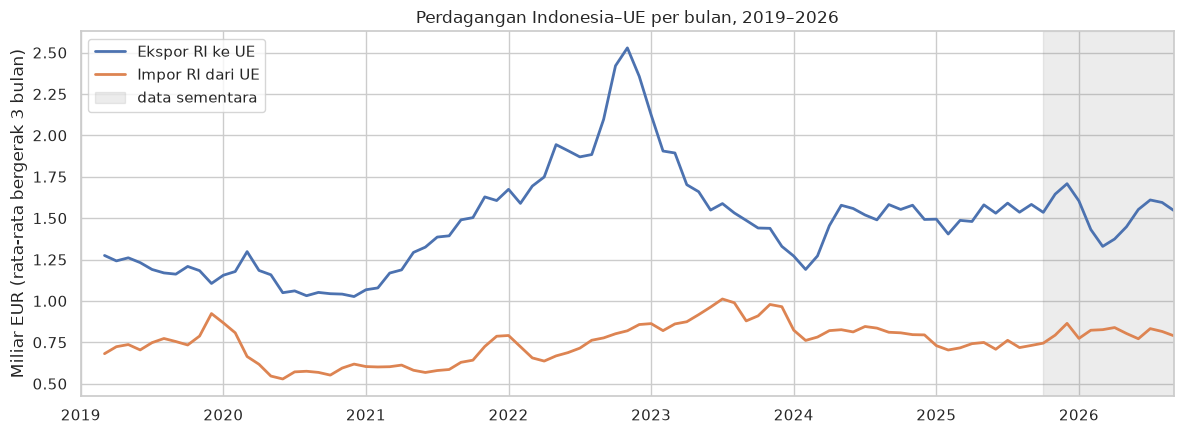

Perbandingan periode sama (Jan–bulan 9):


arus,Ekspor RI ke UE,Impor RI dari UE,Ekspor YoY %
tahun,,,
2019,11.00,6.42,NaN
2020,10.20,5.28,-7.33
2021,11.95,5.40,17.19
2022,17.09,6.36,43.05
2023,14.79,8.11,-13.50
2024,13.24,7.22,-10.48
2025,13.80,6.47,4.24
2026,13.28,7.16,-3.75


,Δ 2021→2022 (miliar EUR),Δ 2022→2023 (miliar EUR),deskripsi_hs2
hs2,,,
27,1.34,-0.66,"MINERAL FUELS, MINERAL OILS AND PRODUCTS OF T"
64,0.89,-0.22,"FOOTWEAR, GAITERS AND THE LIKE; PARTS OF SUCH"
89,0.61,-0.58,"SHIPS, BOATS AND FLOATING STRUCTURES"
38,0.60,-0.66,MISCELLANEOUS CHEMICAL PRODUCTS
72,0.49,-0.53,IRON AND STEEL
85,0.40,-0.14,ELECTRICAL MACHINERY AND EQUIPMENT AND PARTS


In [17]:
tahunan = (df_clean.groupby(['tahun', 'arus'])['nilai_eur'].sum().unstack() / 1e9)
tahunan['Neraca (surplus RI)'] = tahunan['Ekspor RI ke UE'] - tahunan['Impor RI dari UE']
tahunan['Ekspor YoY %'] = tahunan['Ekspor RI ke UE'].pct_change() * 100
n_bulan = df_clean.groupby('tahun')['periode'].nunique()
tahunan['jumlah_bulan'] = n_bulan
display(tahunan.round(2))

bulanan = df_clean.groupby(['periode', 'arus'])['nilai_eur'].sum().unstack() / 1e9
fig, ax = plt.subplots(figsize=(12, 4.5))
bulanan.rolling(3).mean().plot(ax=ax, lw=2)
ax.set_ylabel('Miliar EUR (rata-rata bergerak 3 bulan)'); ax.set_xlabel('')
ax.set_title('Perdagangan Indonesia–UE per bulan, 2019–2026')
ax.axvspan(bulanan.index.max() - pd.DateOffset(months=11), bulanan.index.max(), color='grey', alpha=.15, label='data sementara')
ax.legend(); plt.tight_layout(); plt.savefig('figures/q1_tren.png', dpi=130); plt.show()

# 2026 baru 9 bulan: bandingkan periode yang sama (Jan–Sep) agar adil
bulan_max = df_clean.loc[df_clean['tahun'] == df_clean['tahun'].max(), 'bulan'].max()
ytd = (df_clean[df_clean['bulan'] <= bulan_max].groupby(['tahun', 'arus'])['nilai_eur'].sum().unstack() / 1e9)
ytd['Ekspor YoY %'] = ytd['Ekspor RI ke UE'].pct_change() * 100
print(f'Perbandingan periode sama (Jan–bulan {bulan_max}):'); display(ytd.round(2))

# Siapa pendorong lonjakan 2022 dan penurunan 2023?
per_hs = eks.groupby(['tahun', 'hs2'])['nilai_eur'].sum().unstack(fill_value=0) / 1e9
label = eks.drop_duplicates('hs2').set_index('hs2')['deskripsi_hs2'].str[:45]
kontrib = pd.DataFrame({'Δ 2021→2022 (miliar EUR)': per_hs.loc[2022] - per_hs.loc[2021],
                        'Δ 2022→2023 (miliar EUR)': per_hs.loc[2023] - per_hs.loc[2022]}).join(label)
display(kontrib.nlargest(6, 'Δ 2021→2022 (miliar EUR)').round(2))

**Observation:** Ekspor Indonesia ke UE naik dari EUR 14,3 miliar di 2019 sampai puncaknya EUR 24,2 miliar di 2022 (naik 44% dari tahun sebelumnya). Setelah itu turun lagi ke EUR 18,8 miliar di 2023 dan EUR 18,9 miliar di 2025. Impor dari UE cenderung stabil di kisaran EUR 7 sampai 11 miliar, jadi Indonesia selalu surplus, paling tinggi EUR 15,2 miliar di 2022 dan EUR 9,9 miliar di 2025. Kalau dibandingkan periode yang sama (Januari sampai September), ekspor 2026 sebesar EUR 13,3 miliar, sedikit di bawah 2025 yang EUR 13,8 miliar (turun sekitar 4%), sedangkan impornya naik dari EUR 6,5 ke 7,2 miliar. Penyumbang terbesar lonjakan 2022 adalah batu bara (HS 27, naik EUR 1,3 miliar), lalu alas kaki, kapal, produk kimia dan besi-baja, dan sebagian besar turun lagi di 2023.

**Interpretation:** Menurut saya lonjakan 2022 terjadi karena harga komoditas sedang tinggi dan UE butuh energi saat itu. Batu bara misalnya naik hampir 9 kali lipat, lalu turun lagi setahun kemudian. Tabel tahunan memperlihatkan 2026 turun sekitar 30%, tapi itu karena data 2026 baru 9 bulan. Dengan periode yang sama, ekspor hanya turun sekitar 4%.

**Insight:** Untuk menilai dampak IEU-CEPA nanti (target berlaku 1 Januari 2027), patokan yang lebih masuk akal adalah rata-rata 2023 sampai 2025, sekitar EUR 18 sampai 19 miliar per tahun. Kalau dibandingkan dengan 2022, hasilnya akan kelihatan jelek padahal tahun itu tidak normal. Surplus yang mengecil di Januari sampai September 2026 juga perlu dipantau, apalagi GSP habis akhir 2026 sehingga bisa ada jeda tanpa tarif preferensial kalau ratifikasi terlambat [1].

### Q2. Komoditas apa yang mendominasi ekspor, dan seberapa besar porsi komoditas EUDR?

,hs2,deskripsi_hs2,nilai_eur,pangsa_%,is_eudr
0,15,ANIMAL OR VEGETABLE FATS AND OILS AND THEIR CL...,20.33,14.82,True
1,64,"FOOTWEAR, GAITERS AND THE LIKE; PARTS OF SUCH ...",12.89,9.39,False
2,85,ELECTRICAL MACHINERY AND EQUIPMENT AND PARTS T...,11.31,8.25,False
3,38,MISCELLANEOUS CHEMICAL PRODUCTS,10.70,7.80,False
4,72,IRON AND STEEL,7.46,5.43,False
5,40,RUBBER AND ARTICLES THEREOF,6.26,4.56,True
6,26,"ORES, SLAG AND ASH",4.72,3.44,False
7,62,"ARTICLES OF APPAREL AND CLOTHING ACCESSORIES, ...",4.70,3.43,False
8,84,"NUCLEAR REACTORS, BOILERS, MACHINERY AND MECHA...",4.19,3.05,False
9,27,"MINERAL FUELS, MINERAL OILS AND PRODUCTS OF TH...",3.97,2.90,False


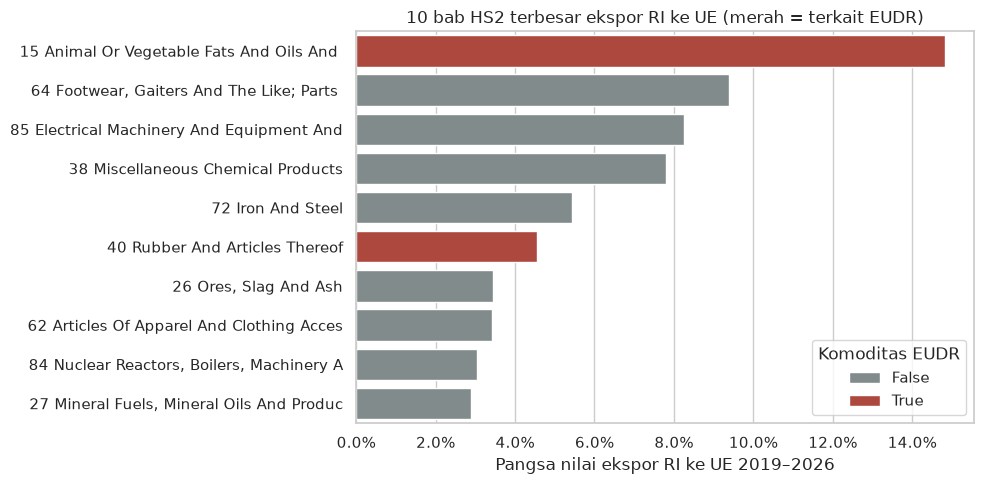

tahun,2019,2020,2021,2022,2023,2024,2025,2026
porsi_EUDR_%,31.30,35.20,33.40,27.00,27.30,28.60,26.70,26.70


In [18]:
top = (eks.groupby(['hs2', 'deskripsi_hs2'])['nilai_eur'].sum().nlargest(10) / 1e9).reset_index()
top['pangsa_%'] = top['nilai_eur'] / (eks['nilai_eur'].sum() / 1e9) * 100
top['label'] = top['hs2'] + ' ' + top['deskripsi_hs2'].str[:38].str.title()
top['is_eudr'] = top['hs2'].isin(df_clean.loc[df_clean['is_eudr'], 'hs2'].unique())
display(top[['hs2', 'deskripsi_hs2', 'nilai_eur', 'pangsa_%', 'is_eudr']].round(2))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top, y='label', x='pangsa_%', hue='is_eudr', dodge=False,
            palette={True: '#c0392b', False: '#7f8c8d'}, ax=ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel('Pangsa nilai ekspor RI ke UE 2019–2026'); ax.set_ylabel('')
ax.set_title('10 bab HS2 terbesar ekspor RI ke UE (merah = terkait EUDR)'); ax.legend(title='Komoditas EUDR')
plt.tight_layout(); plt.savefig('figures/q2_top_hs2.png', dpi=130); plt.show()

porsi = eks.groupby(['tahun', 'is_eudr'])['nilai_eur'].sum().unstack()
porsi = (porsi[True] / porsi.sum(axis=1) * 100).rename('porsi_EUDR_%')
display(porsi.round(1).to_frame().T)

**Observation:** HS 15 (lemak dan minyak, sebagian besar minyak sawit) jadi bab ekspor terbesar dengan pangsa 14,8%, lalu alas kaki (9,4%), mesin listrik (8,3%), produk kimia (7,8%), besi-baja (5,4%) dan karet (4,6%). Porsi komoditas yang terkait EUDR turun dari 31,3% (2019) dan 35,2% (2020) menjadi 26,7% di 2025.

**Interpretation:** Porsi sawit, karet dan kayu di ekspor ke UE pelan-pelan berkurang, sementara alas kaki, elektronik dan besi-baja makin besar. Tapi hampir 27% ekspor masih berupa komoditas yang wajib memenuhi aturan EUDR.

**Insight:** Sekitar seperempat nilai ekspor ke UE bergantung pada kesiapan data ketertelusuran (geolokasi) untuk EUDR yang berlaku 30 Desember 2026 [3][4]. Pendampingan untuk sawit dan karet akan paling terasa dampaknya karena keduanya masuk 10 besar. Alas kaki (9,4%) dan pakaian, yang menurut pemerintah akan diuntungkan oleh penghapusan bea IEU-CEPA [1], sudah termasuk ekspor terbesar sekarang.

### Q3. Apakah komoditas EUDR tumbuh berbeda dari komoditas lain?

komoditas_eudr,Sawit,Karet,Kopi,Kakao,Kayu (furnitur),Kayu (kertas),Bukan EUDR
tahun,,,,,,,
2019,100.00,100.00,100.00,100.00,100.00,100.00,100.00
2020,117.00,90.00,95.00,85.00,97.00,94.00,88.00
2021,139.00,120.00,103.00,100.00,134.00,67.00,114.00
2022,149.00,133.00,152.00,80.00,172.00,149.00,179.00
2023,135.00,87.00,109.00,48.00,108.00,131.00,139.00
2024,121.00,87.00,129.00,127.00,101.00,149.00,129.00
2025,102.00,85.00,240.00,206.00,94.00,172.00,141.00


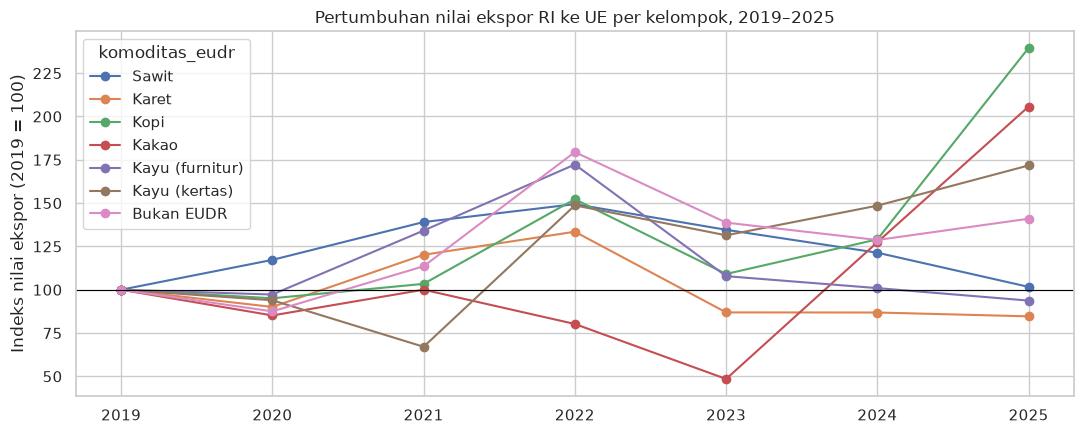

,rate_naik,n
is_eudr,,
False,51.20,73377
True,50.90,14097


In [19]:
g = eks.groupby(['tahun', 'komoditas_eudr'])['nilai_eur'].sum().unstack()
g = g.loc[2019:tahun_penuh]
idx = g.div(g.loc[2019]) * 100     # indeks 2019 = 100
utama = ['Sawit', 'Karet', 'Kopi', 'Kakao', 'Kayu (furnitur)', 'Kayu (kertas)', 'Bukan EUDR']
display(idx[utama].round(0))

fig, ax = plt.subplots(figsize=(11, 4.5))
idx[utama].plot(ax=ax, marker='o')
ax.axhline(100, color='black', lw=.8)
ax.set_ylabel('Indeks nilai ekspor (2019 = 100)'); ax.set_xlabel('')
ax.set_title(f'Pertumbuhan nilai ekspor RI ke UE per kelompok, 2019–{tahun_penuh}')
plt.tight_layout(); plt.savefig('figures/q3_indeks_eudr.png', dpi=130); plt.show()

# Rate target per kelompok (persentase bulan yang naik dibanding tahun lalu)
rate = (eks.dropna(subset=['naik_yoy']).groupby('is_eudr')['naik_yoy']
        .agg(rate_naik='mean', n='size'))
rate['rate_naik'] *= 100
display(rate.round(1))

**Observation:** Dengan 2019 sebagai indeks 100, nilai ekspor di 2025 adalah kopi 240, kakao 206, kertas 172, non-EUDR 141, sawit 102, furnitur kayu 94 dan karet 85. Rate naik_yoy antara kelompok EUDR (50,9%) dan non-EUDR (51,2%) hampir sama.

**Interpretation:** Komoditas EUDR polanya beda-beda. Kopi dan kakao naik tajam, sawit hampir tidak berubah dan karet malah turun, sementara komoditas non-EUDR naik 41%. Persentase bulan yang naik hampir sama di kedua kelompok, jadi perbedaannya ada di seberapa besar kenaikan atau penurunannya.

**Insight:** Sawit dan karet perlu perhatian lebih dibanding kopi dan kakao karena pertumbuhannya tertinggal dari ekspor secara umum. Untuk modeling nanti, kolom is_eudr saja kemungkinan kurang kuat sebagai prediktor, dan kode HS2 yang lebih spesifik akan lebih berguna.

### Q4. Ke negara UE mana ekspor RI masuk, dan seberapa terkonsentrasi?

,miliar_EUR,pangsa_%,kumulatif_%
nama_negara,,,
Belanda,34.39,25.10,25.10
Jerman,20.50,14.90,40.00
Italia,19.23,14.00,54.00
Spanyol,16.77,12.20,66.20
Belgia,13.58,9.90,76.10
Prancis,9.40,6.80,83.00
Polandia,5.51,4.00,87.00
Denmark,2.04,1.50,88.50


Indeks Herfindahl-Hirschman (HHI) negara tujuan: 1,371


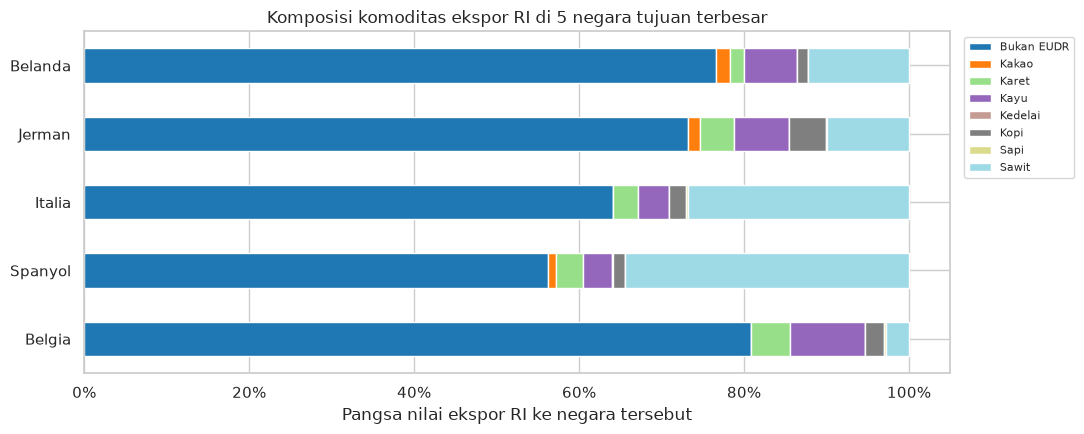

In [20]:
neg = eks.groupby('nama_negara')['nilai_eur'].sum().sort_values(ascending=False)
pangsa = (neg / neg.sum() * 100)
display(pd.DataFrame({'miliar_EUR': (neg / 1e9).round(2), 'pangsa_%': pangsa.round(1),
                      'kumulatif_%': pangsa.cumsum().round(1)}).head(8))
hhi = ((pangsa) ** 2).sum()
print(f'Indeks Herfindahl-Hirschman (HHI) negara tujuan: {hhi:,.0f}')

# Komposisi komoditas di 5 negara terbesar
top5 = neg.index[:5]
kom = (eks[eks['nama_negara'].isin(top5)]
       .assign(kelompok=lambda d: np.where(d['is_eudr'], d['komoditas_eudr'].str.split(' ').str[0], 'Bukan EUDR'))
       .groupby(['nama_negara', 'kelompok'])['nilai_eur'].sum().unstack(fill_value=0))
kom = kom.div(kom.sum(axis=1), axis=0).loc[top5] * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
kom.plot(kind='barh', stacked=True, ax=ax, colormap='tab20')
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel('Pangsa nilai ekspor RI ke negara tersebut'); ax.set_ylabel('')
ax.set_title('Komposisi komoditas ekspor RI di 5 negara tujuan terbesar'); ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.savefig('figures/q4_negara.png', dpi=130); plt.show()

**Observation:** Belanda menyerap 25,1% ekspor Indonesia ke UE, diikuti Jerman (14,9%), Italia (14,0%), Spanyol (12,2%) dan Belgia (9,9%). Kelima negara ini totalnya 76,1%, dengan HHI 1.371 (konsentrasi sedang). Isi ekspornya juga beda-beda: sawit menyumbang 34% ekspor Indonesia ke Spanyol dan 27% ke Italia, tapi cuma 12% ke Belanda dan 3% ke Belgia.

**Interpretation:** Angka Belanda besar kemungkinan karena Rotterdam jadi pelabuhan masuk dan pusat distribusi ke negara UE lain. Data Comext mencatat negara yang melapor, belum tentu negara yang akhirnya memakai barangnya.

**Insight:** Promosi dan diplomasi dagang paling efektif kalau difokuskan ke lima negara ini. Spanyol dan Italia paling terpengaruh isu sawit/EUDR, sedangkan Belanda dan Belgia lebih banyak menerima produk non-EUDR. Negara di luar lima besar seperti Polandia dan negara Eropa Timur bisa jadi peluang untuk diversifikasi.

### Q5. Kenaikan/penurunan komoditas EUDR: karena harga atau volume?

,volume 2019 (rb ton),volume 2025 (rb ton),Δ volume %,harga 2019 (EUR/t),harga 2025 (EUR/t),Δ harga %
hs2,,,,,,
Kopi (HS 09),100.00,131.00,31.00,"2,564.00","4,676.00",82.00
Sawit (HS 15),"3,891.00","1,805.00",-54.00,555.00,"1,217.00",119.00
Kakao (HS 18),51.00,30.00,-42.00,"3,478.00","12,251.00",252.00
Karet (HS 40),457.00,252.00,-45.00,"1,793.00","2,747.00",53.00


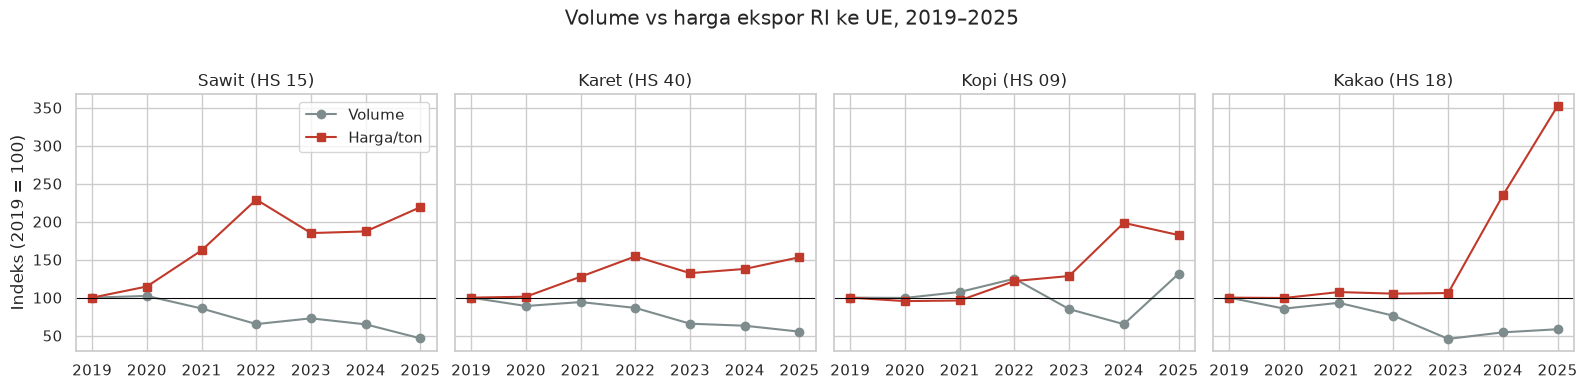

In [21]:
pilih = {'15': 'Sawit (HS 15)', '40': 'Karet (HS 40)', '09': 'Kopi (HS 09)', '18': 'Kakao (HS 18)'}
hv = (eks[eks['hs2'].isin(pilih) & eks['berat_100kg'].notna()]
      .groupby(['hs2', 'tahun']).agg(nilai=('nilai_eur', 'sum'), berat=('berat_100kg', 'sum')))
hv['volume_ribu_ton'] = hv['berat'] * 100 / 1e6
hv['harga_EUR_per_ton'] = hv['nilai'] / (hv['berat'] / 10)
hv = hv.loc[(slice(None), slice(2019, tahun_penuh)), ['volume_ribu_ton', 'harga_EUR_per_ton']]
ringkas = hv.unstack('tahun')
ringkas = pd.DataFrame({
    'volume 2019 (rb ton)': ringkas[('volume_ribu_ton', 2019)],
    f'volume {tahun_penuh} (rb ton)': ringkas[('volume_ribu_ton', tahun_penuh)],
    'Δ volume %': (ringkas[('volume_ribu_ton', tahun_penuh)] / ringkas[('volume_ribu_ton', 2019)] - 1) * 100,
    'harga 2019 (EUR/t)': ringkas[('harga_EUR_per_ton', 2019)],
    f'harga {tahun_penuh} (EUR/t)': ringkas[('harga_EUR_per_ton', tahun_penuh)],
    'Δ harga %': (ringkas[('harga_EUR_per_ton', tahun_penuh)] / ringkas[('harga_EUR_per_ton', 2019)] - 1) * 100,
}).rename(index=pilih)
display(ringkas.round(0))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (kode, nama) in zip(axes, pilih.items()):
    x = hv.loc[kode]; x = x / x.iloc[0] * 100
    ax.plot(x.index, x['volume_ribu_ton'], marker='o', label='Volume', color='#7f8c8d')
    ax.plot(x.index, x['harga_EUR_per_ton'], marker='s', label='Harga/ton', color='#c0392b')
    ax.axhline(100, color='black', lw=.7); ax.set_title(nama)
axes[0].set_ylabel('Indeks (2019 = 100)'); axes[0].legend()
fig.suptitle(f'Volume vs harga ekspor RI ke UE, 2019–{tahun_penuh}', y=1.02)
plt.tight_layout(); plt.savefig('figures/q5_harga_volume.png', dpi=130, bbox_inches='tight'); plt.show()

**Observation:** Dari 2019 ke 2025, volume sawit (HS 15) turun 54% (dari sekitar 3.891 menjadi 1.805 ribu ton), padahal harga per tonnya naik 119%. Volume karet turun 45% dengan harga naik 53%. Volume kakao turun 42% sementara harganya naik sekitar 3,5 kali (+252%). Hanya kopi yang volume (+31%) dan harganya (+82%) sama-sama naik.

**Interpretation:** Nilai sawit yang kelihatan stabil dan nilai kakao yang melonjak sebagian besar datang dari harga. Jumlah barang yang dikirim ke UE untuk sawit, karet dan kakao malah berkurang. Dari data ini saya belum bisa tahu penyebabnya. Bisa karena harga global, kebijakan biofuel UE, persiapan menghadapi EUDR, atau ekspor dialihkan ke negara lain, dan itu perlu diuji dengan data tambahan.

**Insight:** Kalau harga komoditas turun lagi, nilai ekspor sawit, karet dan kakao ke UE bisa anjlok karena volumenya sudah menyusut. EUDR mulai berlaku 30 Desember 2026 untuk kelima komoditas Indonesia yang terdampak (sawit, kopi, kakao, kayu, karet) [4], jadi data bulanan 2027 sebaiknya dipantau volumenya juga, tidak hanya nilainya, untuk melihat apakah penurunannya berlanjut.

### 5.3 Hypothesis


| No | Hypothesis | Berasal dari temuan |
|---|---|---|
| 1 | Penurunan volume sawit dan karet ke UE sejak 2021 lebih besar daripada penurunan ekspor kedua komoditas ini ke pasar non-UE. Kalau benar, berarti ada faktor khusus di pasar UE, misalnya regulasi. Bisa diuji dengan data BPS atau UN Comtrade ke negara lain. | Q3, Q5 |
| 2 | Kenaikan nilai kopi dan kakao di 2024 dan 2025 terutama karena harga global. Kalau pengaruh harga dikeluarkan, pertumbuhan volumenya tidak jauh beda dengan komoditas non-EUDR. | Q3, Q5 |
| 3 | Setelah IEU-CEPA berlaku (target 1 Januari 2027) dan bea untuk lebih dari 90% barang dihapus, pangsa produk padat karya (alas kaki HS 64, pakaian HS 61 dan 62) dalam ekspor ke UE akan naik dibanding baseline 2023 sampai 2025. | Q2, konteks [1] |
| 4 | Riwayat naik/turun beberapa bulan terakhir (lag naik_yoy) dan jenis komoditas (HS2) lebih kuat untuk memprediksi naik_yoy dibanding negara tujuan. | Q3, Q4, profil target |

## Kesimpulan


1. Data Eurostat sudah rapi secara format, tapi tetap perlu dibersihkan dari sisi makna: tipe kode, HS 99, nilai 0, berat 0 karena pembulatan satuan, dan harga satuan ekstrem (yang ini hanya ditandai, tidak dihapus).
2. Ekspor Indonesia ke UE stabil di sekitar EUR 19 miliar per tahun setelah puncak sementara di 2022 yang didorong batu bara dan harga komoditas. Indonesia selalu surplus.
3. Porsi komoditas EUDR turun ke sekitar 27%, dan volume sawit, karet dan kakao menyusut cukup tajam. Nilainya tertolong karena harga.
4. Ekspor terkonsentrasi di lima negara (76%), paling besar ke Belanda.
5. Target naik_yoy seimbang (sekitar 51:49) dan siap dipakai untuk modeling, dengan catatan soal leakage di Bab 3.8 dan pembagian data berdasarkan waktu.
6. Data sampai September 2026 ini bisa jadi baseline untuk mengevaluasi dampak IEU-CEPA dan EUDR mulai 2027.

## Referensi


1. ANTARA News (23 November 2026). *Indonesia seeks wider export access to Europe through IEU-CEPA*. https://en.antaranews.com/news/444627/indonesia-seeks-wider-export-access-to-europe-through-ieu-cepa
2. Kementerian Luar Negeri RI (November 2026). *Indonesia dan Uni Eropa perkuat kemitraan ekonomi melalui IEU-CEPA dan IPA*. https://www.kemlu.go.id/en/berita/indonesia-dan-uni-eropa-perkuat-kemitraan-ekonomi-melalui-ieu-cepa-dan-ipa?type=publication
3. Council of the European Union (18 Desember 2025). *Deforestation: Council signs off targeted revision to simplify and postpone the regulation*. https://www.consilium.europa.eu/en/press/press-releases/2025/12/18/deforestation-council-signs-off-targeted-revision-to-simplify-and-postpone-the-regulation/
4. GAPKI (20 November 2026). *Palm exporters urged to prepare geolocation data for EUDR*. https://gapki.id/en/news/2026/11/20/palm-exporters-prepare-geolocation-data-eudr/
5. Eurostat (2026). *EU trade since 1988 by HS2-4-6 and CN8* (DS-045409), Comext. https://ec.europa.eu/eurostat/comext/ (diakses November 2026; lisensi CC BY 4.0).